# 01 Mesh preprocessing

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from stl import mesh
from os.path import exists, split, join
from os import makedirs

from base.utils import find_neighbours_with_knn, load_ply, list_all_plymeshes, return_rings
from base.LBC_centreline import return_LBC_centreline
from base.refine_centreline import refine


Jupyter environment detected. Enabling Open3D WebVisualizer.
[Open3D INFO] WebRTC GUI backend enabled.
[Open3D INFO] WebRTCWindowSystem: HTTP handshake server disabled.


The first step is to generate a listing of all ply mesh filepaths from a directory. 

In [2]:
# change here the path to the repository of karst catalogue
data_repository = "F:/ScanLeica/data_paper/KarstConduitCatalogue" 
passages_filepaths = list_all_plymeshes(data_repository)

In [3]:
passages_filepaths  

['F:\\ScanLeica\\data_paper\\KarstConduitCatalogue\\Archamps\\PostEtroiture\\mesh\\Archamps_PostEtroiture_mesh_5cm.ply',
 'F:\\ScanLeica\\data_paper\\KarstConduitCatalogue\\Archamps\\PreEtroiture\\mesh\\Archamps_PreEtroiture_mesh_5cm.ply',
 'F:\\ScanLeica\\data_paper\\KarstConduitCatalogue\\BaumeDeLongeaigue\\GrandToboggan\\mesh\\BaumeDeLongeaigue_GrandToboggan_mesh_5cm.ply',
 'F:\\ScanLeica\\data_paper\\KarstConduitCatalogue\\CascadeDeMotiers\\MainGallery\\mesh\\CascadeDeMotiers_MainGallery_mesh_5cm.ply',
 'F:\\ScanLeica\\data_paper\\KarstConduitCatalogue\\CocaliereCotepatiere\\AvenDeLaCocaliere1\\mesh\\CocaliereCotepatiere_AvenDeLaCocaliere1_mesh_5cm.ply',
 'F:\\ScanLeica\\data_paper\\KarstConduitCatalogue\\CocaliereCotepatiere\\AvenDeLaCocaliere2\\mesh\\CocaliereCotepatiere_AvenDeLaCocaliere2_mesh_5cm.ply',
 'F:\\ScanLeica\\data_paper\\KarstConduitCatalogue\\CocaliereCotepatiere\\AvenDeLaCocaliere3\\mesh\\CocaliereCotepatiere_AvenDeLaCocaliere3_mesh_5cm.ply',
 'F:\\ScanLeica\\data_p

In [4]:
idx = 22

In [5]:
plymesh_filepath =  passages_filepaths[idx]
stlmesh_filepath = plymesh_filepath[:-3]+"stl"

The first step is to use a stl.mesh.Mesh() object to do our calculations with. 

In [6]:
keepfile = True # change to false to regenerate a clean stl mesh file.

if exists(stlmesh_filepath) and keepfile==True:
    # if there exists already a file in stl format.
    mesh_data = mesh.Mesh.from_file(stlmesh_filepath)
else:
    mesh_data = load_ply(plymesh_filepath)
    mesh_data.save(stlmesh_filepath)

100%|█████████████████████████████████████████████████████████████████████| 8988580/8988580 [01:36<00:00, 93406.45it/s]


Now that we have a mesh object, we can query it easily. In numpy-stl.mesh.Mesh() objects, the surface is defined by the .vectors attribute, an array of triangle vertex coordinates whose shape is the following (ntriangles, 3, 3). By calling the method .update_normals() and .update_centroids(), we can recompute the face normals and their centroids, storing them in separate attributes.

In [7]:
# not strictly necessary at this stage, but can be done.
update = False

if update:
    mesh_data.update_centroids() 
    mesh_data.update_normals()

One thing we can do is to extract the mesh faces centroids and plot them as a point cloud.

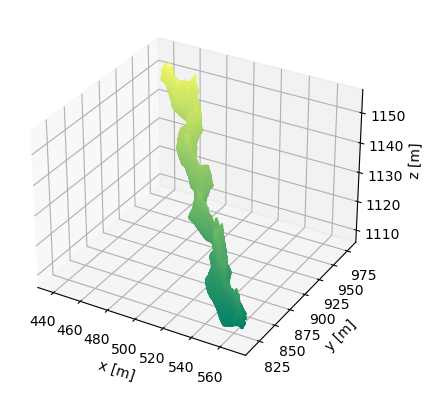

In [8]:
fig = plt.figure() 

ax = fig.add_subplot(projection="3d")

ax.scatter(*mesh_data.centroids[::100, [0, 1, 2]].T, s=0.5, c = mesh_data.vectors[::100, 1, 2], cmap = "summer")
ax.set_xlabel("x [m]")
ax.set_ylabel("y [m]")
ax.set_zlabel("z [m]")

plt.show()

Another preprocessing step we might have to perform is the following: to compute a matrix of triangle adjacency from the mesh. This is calculated once and can be reused for the intersection computations. 

In [9]:
keep_triangles = True
adj_triangles_filepath = stlmesh_filepath[:-4] + "_adjacent_triangles.txt"

if exists(adj_triangles_filepath) and keep_triangles == True:
    adjacent_triangles = np.loadtxt(adj_triangles_filepath)
else:
    adjacent_triangles = find_neighbours_with_knn(mesh_data)
    np.savetxt  
    (adj_triangles_filepath, adjacent_triangles)

knn search complete and neighbouring triangles found in 1210.7514s (8988580 triangle neighbour sets.)


Finally, we can generate or reuse an existing centreline.

In [10]:
centreline_directory = join(split(passages_filepaths[idx])[0][:-5], "geometric_descriptors")

if exists(centreline_directory):
    print("centreline directory exists already.")
else:
    makedirs(centreline_directory)

centreline_filepath = join(centreline_directory, split(passages_filepaths[idx])[1][:-12]+"centreline.txt")

In [11]:
keep_centreline = False
refine_centreline = True

if exists(centreline_filepath) and keep_centreline:
    centreline = np.loadtxt(centreline_filepath, skiprows=1)
    
    if refine_centreline:
        distances = np.linalg.norm(np.diff(centreline, axis = 0), axis = 1)

        # by how much to refine. 
        while np.max(distances) > 1.5 * np.median(distances):
            centreline  = refine(centreline, 1)
            distances = np.linalg.norm(np.diff(centreline, axis = 0), axis = 1)
        np.savetxt(centreline_filepath, centreline, header="X, Y, Z")

else:
    lbc_args = dict(init_attraction = 4, 
                    init_contraction = 0.5, 
                    down_sample = 0.7)

    ct_args = dict(centreline_down_sample= 0.7, 
                   keep_adjacent_triangles=True)

    LBC_result = return_LBC_centreline(stlmesh_filepath, 
                                    adj_triangles_filepath, 
                                    lbc_args=lbc_args, 
                                    ct_args=ct_args)

    centreline = LBC_result["centreline"]
    
    if refine_centreline:
        distances = np.linalg.norm(np.diff(centreline, axis = 0), axis = 1)

        # by how much to refine. 
        while np.max(distances) > 1.5 * np.median(distances):
            centreline  = refine(centreline, 1)
            distances = np.linalg.norm(np.diff(centreline, axis = 0), axis = 1)
        
    np.savetxt(centreline_filepath, centreline, header="X, Y, Z")

knn search complete and neighbouring triangles found in 1194.3758s (8988580 triangle neighbour sets.)
read file in 0.0000s


2025-05-21 12:17:25,048 - PCD #points: 19813


contracted file in 11.6690s


Volume ratio: 0.2523140085241752. Contraction weights: 2048.0. Attraction weights: 296.6610742955964. Progress LBC:  202025-05-21 12:17:34,033 - Contraction is Done.
Volume ratio: 0.2523140085241752. Contraction weights: 2048.0. Attraction weights: 296.6610742955964. Progress LBC:  20

Contraction is Done.
extracted skeleton in 9.0412s
downsampled the centreline cloud in 0.0080s
there were 0 connected components.
found largest component in 0.0309s
computed minimum spanning tree in 0.0060s
created graph instance of the centreline in  0.0000s
added node coordinates to graph in  0.0010s


there were 18 rings found
computed the longest of all shortest path permutations in  2.3022s


Find the rings of the mesh as these correspond to potential inlets and outlets.

In [12]:
rings = return_rings(mesh_data, adjacent_triangles)

In [13]:
rings

{'ring1': array([[ 566.92377,  822.5772 , 1109.2352 ],
        [ 566.9869 ,  822.59595, 1109.2352 ],
        [ 567.0201 ,  822.61646, 1109.2186 ],
        ...,
        [ 564.05634,  820.2347 , 1113.6187 ],
        [ 564.1447 ,  820.2819 , 1114.1576 ],
        [ 564.94794,  820.96265, 1114.7853 ]], dtype=float32),
 'P1': array([ 563.9309 ,  820.13855, 1111.2496 ], dtype=float32),
 'nP1': array([-6.300871e-01,  7.765244e-01, -2.967762e-04], dtype=float32),
 'ring2': array([[ 465.81848,  973.87933, 1146.317  ],
        [ 465.84473,  973.8626 , 1146.3217 ],
        [ 466.02103,  973.7365 , 1146.3083 ],
        ...,
        [ 463.39218,  975.5627 , 1150.8186 ],
        [ 463.8741 ,  975.3521 , 1151.0853 ],
        [ 463.8768 ,  975.3498 , 1151.4186 ]], dtype=float32),
 'P2': array([ 462.72455,  975.48114, 1148.1265 ], dtype=float32),
 'nP2': array([-0.38992152, -0.91790974,  0.07350437], dtype=float32),
 'ring3': array([[ 440.04663,  978.98444, 1148.4044 ],
        [ 438.7947 ,  977.7293 , 

Text(0.5, 0, 'X [m]')

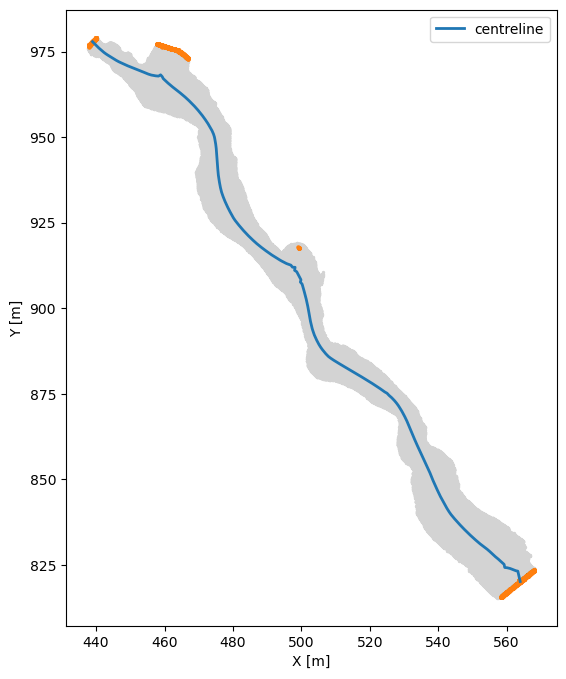

In [14]:
fig, ax = plt.subplots(figsize=(8, 8))

ax.scatter(*mesh_data[::100, [0,1]].T, color = "lightgrey", s = 2)

ax.plot(*centreline[:, [0,1]].T, zorder = 100, lw = 2, label = "centreline")
for key, value in rings.items():
    if "ring" in key:
        ax.scatter(*value[:, [0,1]].T, color="C1", s=5)
        
ax.set_aspect("equal")
ax.legend()
ax.set_ylabel("Y [m]")
ax.set_xlabel("X [m]")

In [15]:
# now we put everything in one big loop to process all the datasets. 
